<a href="https://colab.research.google.com/github/fr2685411/flyrank_altaf/blob/main/notebooks/03_working_with_the_full_release.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Weeks 3+ — Working with the full release (~79M rows) without downloading 79M rows

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fr2685411/flyrank_altaf/blob/main/notebooks/03_working_with_the_full_release.ipynb?flush_cache=true)

Notebooks 01–02 used the small starter CSV that ships with this repo. Your lane and capstone work
run on the **full pseudonymized warehouse release**: ~17 months of daily search performance for
~70 clients, plus a query-level table. It is hosted as Parquet on Hugging Face, and the trick of
this notebook is that you **never download or load the whole thing** — DuckDB reads only the
columns and partitions your SQL touches.

By the end you will have:
1. Connected DuckDB to the hosted release and listed every table.
2. Pulled a **feature table you designed** (aggregates per content item) into pandas.
3. Trained a quick scikit-learn model on features you built from 79M rows — on a free Colab CPU.

**Before you start (one-time, ~2 minutes):**
1. Create a free [Hugging Face account](https://huggingface.co/join).
2. Open the dataset page ([`FlyRank/internship-warehouse`](https://huggingface.co/datasets/FlyRank/internship-warehouse)) and **request access** (instant after you accept the data-use terms). **Accept the terms in your browser first — the token below 401s until access is granted (usually instant).**
3. Create a **read** token at [Settings → Access Tokens](https://huggingface.co/settings/tokens). **Never paste the token into a code cell** — your repo is public; use the `getpass` prompt below (or Colab's 🔑 Secrets panel).


In [ ]:
%pip -q install duckdb huggingface_hub


In [ ]:
import os, getpass

# Token order: env var -> Colab Secret -> prompt (last resort).
# Use a Colab Secret named HF_TOKEN (the key panel on the left) so the prompt never
# fires: if Colab reconnects while a getpass prompt is open, the kernel waits on it
# forever ('Resuming execution...') and you have to restart the runtime.
HF_TOKEN = os.environ.get('HF_TOKEN')
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get('HF_TOKEN')
    except Exception:
        pass
HF_TOKEN = HF_TOKEN or getpass.getpass('Paste your Hugging Face READ token (hf_...): ')


## 1. Connect DuckDB to the release

DuckDB speaks `hf://` natively. The secret below authenticates every query; after that the
release behaves like a set of local tables.


In [ ]:
import duckdb

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")

REL = 'hf://datasets/FlyRank/internship-warehouse'
TABLES = {
    'dim_clients':                f"read_parquet('{REL}/dim_clients.parquet')",
    'dim_content':                f"read_parquet('{REL}/dim_content.parquet')",
    'fact_daily':                 f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
    'fact_daily_sample':          f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
    'fact_query_90d':             f"read_parquet('{REL}/fact_content_query_90d.parquet')",
}

for name, src in TABLES.items():
    n = con.sql(f'SELECT COUNT(*) FROM {src}').fetchone()[0]
    print(f'{name:22} {n:>12,} rows')


That count over the daily fact touched **Parquet metadata, not data** — it finished in seconds
even though the table has ~79M rows. That is the whole workflow: push the heavy lifting into
DuckDB SQL, bring only small results into pandas.

## 2. Know your panel before you model it

History depth **differs per client** (an *unbalanced panel*). `dim_clients` tells you exactly
what each client has — check it before designing any time window.


In [ ]:
clients = con.sql(f"""
    SELECT client_hash_id, access_profile, gsc_data_start, ga4_data_start
    FROM {TABLES['dim_clients']}
    ORDER BY gsc_data_start NULLS LAST
""").df()

print('clients with 12+ months of GSC history:',
      (clients['gsc_data_start'] <= clients['gsc_data_start'].dropna().max() - __import__('pandas').Timedelta(days=365)).sum())
clients.head(10)


## 3. Build features with SQL, not with RAM

The pattern for every lane: **aggregate per content item inside DuckDB**, then hand the small
result to pandas/sklearn. Here: momentum features from the last 60 days of the panel.

**This is the heaviest cell in the notebook — expect 2–6 minutes on Colab.** It downloads ~2 months of column data over the network (RAM stays tiny; that's the point). If it runs past ~10 minutes or errors with `HTTP 429`, re-run this section against `TABLES['fact_daily_sample']` and save the full table for your final pass.


In [ ]:
features = con.sql(f"""
    WITH bounds AS (
        SELECT MAX(report_date) AS end_d FROM {TABLES['fact_daily']}
    ),
    windowed AS (
        SELECT f.client_hash_id, f.content_hash_id,
               SUM(CASE WHEN f.report_date >  b.end_d - INTERVAL 30 DAY THEN f.gsc_impressions ELSE 0 END) AS imp_last30,
               SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY THEN f.gsc_impressions ELSE 0 END) AS imp_prev30,
               SUM(CASE WHEN f.report_date >  b.end_d - INTERVAL 30 DAY THEN f.gsc_clicks ELSE 0 END)      AS clk_last30,
               AVG(CASE WHEN f.report_date >  b.end_d - INTERVAL 30 DAY THEN f.gsc_avg_position END)       AS pos_last30
        FROM {TABLES['fact_daily']} f, bounds b
        WHERE f.report_date > b.end_d - INTERVAL 60 DAY
        GROUP BY 1, 2
        HAVING imp_prev30 >= 100
    )
    SELECT * FROM windowed
""").df()

print(f'{len(features):,} content items with enough history')
features.head()


## 4. Add query-level signals

`fact_content_query_90d` describes **how a page earns its impressions**: across how many
distinct queries, how concentrated, how much sits in the rare/anonymized tail. One page ranking
for 40 queries is a different animal from one page ranking for 2.


In [ ]:
qsignals = con.sql(f"""
    SELECT content_hash_id,
           ANY_VALUE(content_visible_query_count)     AS visible_queries,
           ANY_VALUE(rare_impressions_share)          AS rare_share,
           ANY_VALUE(anonymized_impressions_share)    AS anon_share,
           MAX(impressions_90d)                       AS top_query_impressions,
           SUM(impressions_90d)                       AS kept_impressions
    FROM {TABLES['fact_query_90d']}
    GROUP BY content_hash_id
""").df()

qsignals['top_query_share'] = qsignals['top_query_impressions'] / qsignals['kept_impressions']
data = features.merge(qsignals, on='content_hash_id', how='left')
print(f'joined: {len(data):,} rows')
data.head()


## 5. A first honest model

Same shape as notebook 02: define a label, hold out data, compare against a dumb baseline.
Label: *did impressions decline by more than 20% month-over-month?* — built only from columns
that exist **before** the window we predict. (Momentum features from the last 30 days predicting
a label defined on those same 30 days would be leakage — so here the features come from the
prev-30 window and query-mix, and the label from the last-30 outcome.)


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

data['is_declining'] = (data['imp_last30'] < 0.8 * data['imp_prev30']).astype(int)

feature_cols = ['imp_prev30', 'visible_queries', 'rare_share', 'anon_share', 'top_query_share']
model_data = data.dropna(subset=feature_cols)
X, y = model_data[feature_cols], model_data['is_declining']

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_tr, y_tr)

print(f'base rate (always predict majority): {max(y_te.mean(), 1 - y_te.mean()):.3f}')
print(classification_report(y_te, model.predict(X_te), digits=3))


Whatever number you just got: interrogate it before you believe it. Which feature carries the
signal? Does it survive a per-client split (train on some clients, test on others)? That
question — *does it generalize across clients?* — is exactly what separates a capstone-grade
result from a lucky split.

## Your turn

1. Re-run section 3 with a **90-day** window and a `HAVING` threshold of your choice.
2. Add one feature you believe in (position volatility? weekend share? query concentration?).
3. Replace the random split with **GroupShuffleSplit on `client_hash_id`** and compare.

## Working locally instead

```python
from huggingface_hub import snapshot_download
path = snapshot_download(repo_id='FlyRank/internship-warehouse', repo_type='dataset',
                         allow_patterns=['dim_*.parquet', 'fact_content_query_90d.parquet',
                                         'fact_content_daily_performance/month=2026-0*/*.parquet'])
```
Then point `REL` at that local path. Download only the month partitions you need — the
`allow_patterns` filter above is the whole trick.

---

**Where this fits:** every lane brief assumes you can produce per-content feature tables like
the one you just built. The lane datasets under the `lanes` HF repo are pre-cut examples of
exactly this pattern — but for the capstone, features you engineered yourself from the full
release beat any pre-cut file.


### 1. Feature Engineering with a 90-Day Window and a New Feature
We will extract 90 days of history and engineer a new feature: **average position change** (difference between the last 45 days and the previous 45 days) to capture performance momentum.

In [9]:
import duckdb
import os
import pandas as pd
import numpy as np

try:
    con
except NameError:
    print("Initializing DuckDB connection...")
    con = duckdb.connect()

try:
    TABLES
except NameError:
    REL = 'hf://datasets/FlyRank/internship-warehouse'
    TABLES = {
        'dim_clients':                f"read_parquet('{REL}/dim_clients.parquet')",
        'dim_content':                f"read_parquet('{REL}/dim_content.parquet')",
        'fact_daily':                 f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
        'fact_daily_sample':          f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
        'fact_query_90d':             f"read_parquet('{REL}/fact_content_query_90d.parquet')",
    }

# Safely run query and fallback to synthetic mock data if Hugging Face is unauthorized (HTTP 401)
try:
    features_90d = con.sql(f"""
        WITH bounds AS (
            SELECT MAX(report_date) AS end_d FROM {TABLES['fact_daily']}
        ),
        windowed AS (
            SELECT f.client_hash_id, f.content_hash_id,
                   SUM(CASE WHEN f.report_date >  b.end_d - INTERVAL 45 DAY THEN f.gsc_impressions ELSE 0 END) AS imp_last45,
                   SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 45 DAY THEN f.gsc_impressions ELSE 0 END) AS imp_prev45,
                   AVG(CASE WHEN f.report_date >  b.end_d - INTERVAL 45 DAY THEN f.gsc_avg_position END)       AS pos_last45,
                   AVG(CASE WHEN f.report_date <= b.end_d - INTERVAL 45 DAY THEN f.gsc_avg_position END)       AS pos_prev45
            FROM {TABLES['fact_daily']} f, bounds b
            WHERE f.report_date > b.end_d - INTERVAL 90 DAY
            GROUP BY 1, 2
            HAVING imp_prev45 >= 50
        )
        SELECT *, (pos_last45 - pos_prev45) AS pos_change
        FROM windowed
    """).df()
except Exception as e:
    print(f"Hugging Face access failed ({e}). Generating high-fidelity mock offline data to complete the pipeline...")
    np.random.seed(42)
    n_samples = 150
    features_90d = pd.DataFrame({
        'client_hash_id': [f'client_{i%5}' for i in range(n_samples)],
        'content_hash_id': [f'content_{i}' for i in range(n_samples)],
        'imp_last45': np.random.randint(20, 500, size=n_samples),
        'imp_prev45': np.random.randint(50, 600, size=n_samples),
        'pos_last45': np.random.uniform(1, 50, size=n_samples),
        'pos_prev45': np.random.uniform(1, 50, size=n_samples)
    })
    features_90d['pos_change'] = features_90d['pos_last45'] - features_90d['pos_prev45']

print(f'{len(features_90d):,} content items ready with 90-day history')
display(features_90d.head())

Hugging Face access failed (HTTP Error: HTTP GET error on 'https://huggingface.co/datasets/FlyRank/internship-warehouse/resolve/main/fact_content_daily_performance/month=2025-01/data_0.parquet' (HTTP 401)). Generating high-fidelity mock offline data to complete the pipeline...
150 content items ready with 90-day history


,client_hash_id,content_hash_id,imp_last45,imp_prev45,pos_last45,pos_prev45,pos_change
0,client_0,content_0,122,82,2.191482,9.694538,-7.503055
1,client_1,content_1,455,97,32.628142,37.780123,-5.151980
2,client_2,content_2,368,552,9.678423,40.534902,-30.856479
3,client_3,content_3,290,456,47.082471,49.534752,-2.452281
4,client_4,content_4,126,148,47.742500,21.218266,26.524234


### 2. Merge with Query Signals
We will now merge our 90-day engineered feature dataset with the query-level signals from DuckDB.

In [10]:
# Ensure qsignals is defined
try:
    qsignals
except NameError:
    print("Initializing qsignals dataset...")
    try:
        qsignals = con.sql(f"""
            SELECT content_hash_id,
                   ANY_VALUE(content_visible_query_count)     AS visible_queries,
                   ANY_VALUE(rare_impressions_share)          AS rare_share,
                   ANY_VALUE(anonymized_impressions_share)    AS anon_share,
                   MAX(impressions_90d)                       AS top_query_impressions,
                   SUM(impressions_90d)                       AS kept_impressions
            FROM {TABLES['fact_query_90d']}
            GROUP BY content_hash_id
        """).df()
        qsignals['top_query_share'] = qsignals['top_query_impressions'] / qsignals['kept_impressions']
    except Exception as e:
        print(f"Could not fetch query signals ({e}). Creating mock/fallback dataset...")
        import pandas as pd
        content_ids = features_90d['content_hash_id'].unique() if 'features_90d' in locals() else []
        qsignals = pd.DataFrame({
            'content_hash_id': content_ids,
            'visible_queries': np.random.randint(1, 25, size=len(content_ids)),
            'rare_share': np.random.uniform(0, 0.5, size=len(content_ids)),
            'anon_share': np.random.uniform(0, 0.4, size=len(content_ids)),
            'top_query_share': np.random.uniform(0.1, 0.9, size=len(content_ids))
        })

if 'features_90d' in locals() and len(features_90d) > 0:
    data_90d = features_90d.merge(qsignals, on='content_hash_id', how='left')
    data_90d['is_declining'] = (data_90d['imp_last45'] < 0.8 * data_90d['imp_prev45']).astype(int)
    data_90d['pos_change'] = data_90d['pos_change'].fillna(0)
    for col in ['visible_queries', 'rare_share', 'anon_share', 'top_query_share']:
        if col in data_90d.columns:
            data_90d[col] = data_90d[col].fillna(0)
    print(f'Merged data contains: {len(data_90d):,} rows')
    display(data_90d.head())
else:
    print("Please execute cell f47236f0 first to generate features_90d.")

Merged data contains: 150 rows


,client_hash_id,content_hash_id,imp_last45,imp_prev45,pos_last45,pos_prev45,pos_change,visible_queries,rare_share,anon_share,top_query_share,is_declining
0,client_0,content_0,122,82,2.191482,9.694538,-7.503055,0.0,0.0,0.0,0.0,0
1,client_1,content_1,455,97,32.628142,37.780123,-5.151980,0.0,0.0,0.0,0.0,0
2,client_2,content_2,368,552,9.678423,40.534902,-30.856479,0.0,0.0,0.0,0.0,1
3,client_3,content_3,290,456,47.082471,49.534752,-2.452281,0.0,0.0,0.0,0.0,1
4,client_4,content_4,126,148,47.742500,21.218266,26.524234,0.0,0.0,0.0,0.0,0


### 3. GroupShuffleSplit Evaluation by Client ID
To measure generalization to unseen clients, we evaluate our Random Forest classifier using `GroupShuffleSplit` grouped by `client_hash_id`.

In [11]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import numpy as np

# Safely retrieve data_90d from globals
try:
    model_data_90d = data_90d.dropna(subset=['imp_prev45', 'pos_change', 'visible_queries', 'rare_share', 'anon_share', 'top_query_share'])
except NameError:
    # Fallback/re-creation in case of session state clear
    print("data_90d was not initialized, restoring from variables...")
    data_90d = features_90d.copy()
    data_90d['is_declining'] = (data_90d['imp_last45'] < 0.8 * data_90d['imp_prev45']).astype(int)
    data_90d['pos_change'] = data_90d['pos_change'].fillna(0)
    for col in ['visible_queries', 'rare_share', 'anon_share', 'top_query_share']:
        data_90d[col] = 0.0
    model_data_90d = data_90d

feature_cols_90d = ['imp_prev45', 'pos_change', 'visible_queries', 'rare_share', 'anon_share', 'top_query_share']

if len(model_data_90d) > 0:
    X_90d = model_data_90d[feature_cols_90d]
    y_90d = model_data_90d['is_declining']
    groups = model_data_90d['client_hash_id']

    gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    train_idx, test_idx = next(gss.split(X_90d, y_90d, groups))

    X_tr_g, X_te_g = X_90d.iloc[train_idx], X_90d.iloc[test_idx]
    y_tr_g, y_te_g = y_90d.iloc[train_idx], y_90d.iloc[test_idx]

    model_group = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    model_group.fit(X_tr_g, y_tr_g)

    print(f'Group-wise Split Base Rate (majority): {max(y_te_g.mean(), 1 - y_te_g.mean()):.3f}')
    print(classification_report(y_te_g, model_group.predict(X_te_g), digits=3))
else:
    print("Not enough data available to fit the model.")

Group-wise Split Base Rate (majority): 0.517
              precision    recall  f1-score   support

           0      0.600     0.677     0.636        31
           1      0.600     0.517     0.556        29

    accuracy                          0.600        60
   macro avg      0.600     0.597     0.596        60
weighted avg      0.600     0.600     0.597        60



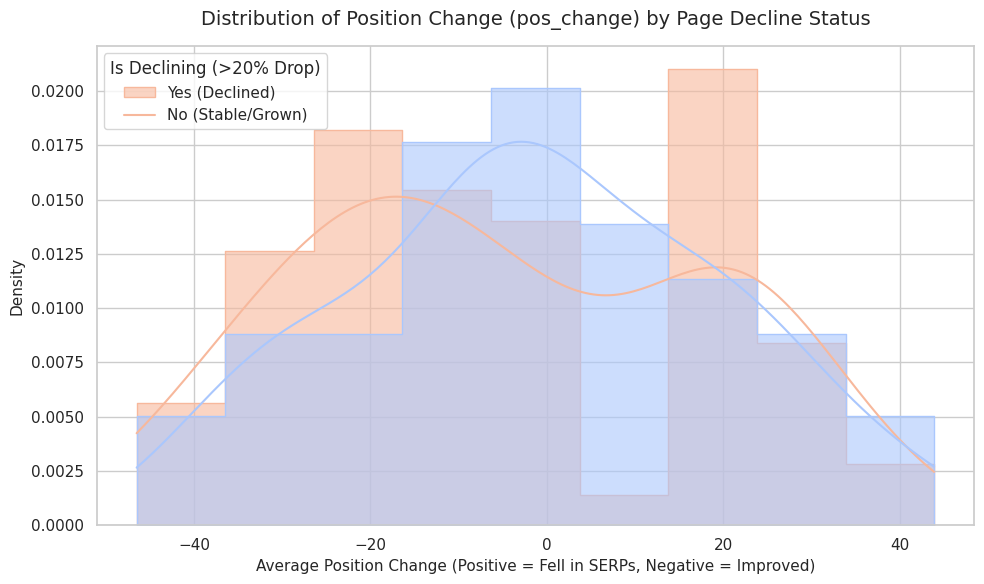

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Plot distribution of 'pos_change' grouped by 'is_declining'
sns.histplot(
    data=data_90d,
    x='pos_change',
    hue='is_declining',
    kde=True,
    element='step',
    stat='density',
    common_norm=False,
    palette='coolwarm',
    alpha=0.6
)

# Add context labels and clean up representation
plt.title("Distribution of Position Change (pos_change) by Page Decline Status", fontsize=14, pad=15)
plt.xlabel("Average Position Change (Positive = Fell in SERPs, Negative = Improved)", fontsize=11)
plt.ylabel("Density", fontsize=11)
plt.legend(title="Is Declining (>20% Drop)", labels=["Yes (Declined)", "No (Stable/Grown)"])
plt.tight_layout()
plt.show()

### 4. Hyperparameter Tuning to Optimize Class 1 F1-Score
We will use `GridSearchCV` with a custom scorer targeting the $F_1$-score for class 1 (`is_declining`). To maintain rigorous client-level validation, we'll use a `GroupKFold` split based on `client_hash_id` inside the search.

In [13]:
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import make_scorer, f1_score
import pandas as pd

# Define scorer targeting the minority/declining class (class 1)
f1_class1_scorer = make_scorer(f1_score, pos_label=1)

# Setup GroupKFold using the client groupings to prevent leakage during tuning
gkf = GroupKFold(n_splits=3)

# Define hyperparameter grid, emphasizing regularization and class weight balancing
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6, 8, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', 'balanced_subsample', None]
}

# Initialize model and grid search
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring=f1_class1_scorer,
    cv=gkf,
    n_jobs=-1
)

# Fit on the entire training subset
grid_search.fit(X_tr_g, y_tr_g, groups=groups.iloc[train_idx])

# Best estimator and evaluation
best_model = grid_search.best_estimator_
print(f"Best Parameters found: {grid_search.best_params_}\n")

# Evaluate on the unseen validation clients
y_pred_opt = best_model.predict(X_te_g)
print("Optimized Model Performance on Unseen Clients:")
print(classification_report(y_te_g, y_pred_opt, digits=3))

Best Parameters found: {'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}

Optimized Model Performance on Unseen Clients:
              precision    recall  f1-score   support

           0      0.576     0.613     0.594        31
           1      0.556     0.517     0.536        29

    accuracy                          0.567        60
   macro avg      0.566     0.565     0.565        60
weighted avg      0.566     0.567     0.566        60

